In [47]:
%reset -f

In [48]:
import os
import re
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path


In [49]:
# --- Trajectory directory configuration ---
# Set the base directories containing the trajectory text files and else

original_dir = os.getcwd()
print("Original directory:", original_dir)

shape = "Sphere"  # Sphere, Ellipsoid, Cylinder

TRAJ_DIR = "../Result_Files/Sphere/Quant_Files/" #Sphere, Ellipsoid, Cylinder
target_shape = "sphere"  # sphere, ellipsoid, cylinder

OUT_DIR = Path(original_dir) / "Time_Plots"
OUT_DIR.mkdir(exist_ok=True)
print("Reading trajectories from:", TRAJ_DIR)
print("Saving plots to:", OUT_DIR)
combined_data_file = os.path.abspath(f"../Result_Files/{shape}/combined_nurse_cell_activation_{target_shape}.txt")


Original directory: /home/pkumar/Documents/Gitlab_INRIA/oocyte-selection-3d-abm/Codes/run/notebooks_post_processing
Reading trajectories from: ../Result_Files/Sphere/Quant_Files/
Saving plots to: /home/pkumar/Documents/Gitlab_INRIA/oocyte-selection-3d-abm/Codes/run/notebooks_post_processing/Time_Plots


In [50]:
# ------------------------------------------------------------------
# Configuration
# ------------------------------------------------------------------
TRAJ_GLOB = "trajectory_" + target_shape + "_s_PTN_*_ESC_*_A_*_B_*_Run_*.txt"  

COLUMN_MAP = {
    9: "Radius",                       # Column 10 in file = index 9
    12: "GERM",                        # Column 13 in file = index 12
    13: "NBD_Score",                   # GERM_NBD_SPHERICAL  
    14: "NurseActivation",             # NURSE_CELL_ACTIVATION
    20: "TotalGermNbdCount",           # TOTAL_GERM_NBD_COUNT
    21: "TotalSomaticNbdCount",        # TOTAL_SOMATIC_NBD_COUNT
}

FEATURES_OF_INTEREST = list(COLUMN_MAP.values())
PARAM_SURFACE_TIMES = [0, 10, 20, 50, 100]

# Filenames  include several extra parameter blocks between B and Run, so allow anything in between.
FILENAME_RE = re.compile(
    r"PTN_(?P<ptn>[\d\.]+)_ESC_(?P<esc>[\d\.]+)_A_(?P<a>[\d\.]+)_B_(?P<b>[\d\.]+).*?_Run_(?P<run>\d+)" ,
)
print(f"Looking for trajectories matching pattern '{TRAJ_GLOB}' inside {TRAJ_DIR}")


Looking for trajectories matching pattern 'trajectory_sphere_s_PTN_*_ESC_*_A_*_B_*_Run_*.txt' inside ../Result_Files/Sphere/Quant_Files/


In [51]:
# Load one trajectory file to extract GERM cell radius as global variable
pattern = os.path.join(TRAJ_DIR, TRAJ_GLOB)
files = glob.glob(pattern)

if files:
    # Take the first trajectory file
    first_file = files[0]
    print(f"Reading trajectory file: {os.path.basename(first_file)}")
    
    GERM_CELL_RADIUS = None
    
    try:
        with open(first_file, 'r') as f:
            for line in f:
                line = line.strip()
                if not line or line.startswith('!') or line.startswith('#') or line.startswith('$'):
                    continue
                
                parts = line.split()
                if len(parts) < 22:
                    continue
                
                try:
                    # Check if this is a GERM cell (GERM value = 1 at column index 12)
                    germ_value = float(parts[12])
                    if germ_value == 1.0:
                        # Extract radius from column index 9
                        radius = float(parts[9])
                        GERM_CELL_RADIUS = radius
                        print(f"Found GERM cell radius: {GERM_CELL_RADIUS}")
                        break
                except (ValueError, TypeError, IndexError):
                    continue
                    
    except Exception as e:
        print(f"Error reading trajectory file: {e}")
    
    if GERM_CELL_RADIUS is None:
        print("Warning: Could not find GERM cell radius in trajectory file")
        GERM_CELL_RADIUS = 1.0  # Set default value
        
else:
    print("No trajectory files found, giviing the value which was seen previous, but check it again")
    GERM_CELL_RADIUS = 2.76  # Set default value

print(f"Global GERM_CELL_RADIUS set to: {GERM_CELL_RADIUS}")

Reading trajectory file: trajectory_sphere_s_PTN_0.40_ESC_50.00_A_0.03_B_0.20_SF_1.000_RNF_0.200_d0_0.100_d1_0.0200_a0_1.000_a1_10.00_a2_2.500_d02_0.100_Phi_-1.000_i11_5.00_i12_-4.000_i21_-8.000_i22_5.00_Run_7.txt
Found GERM cell radius: 2.76
Global GERM_CELL_RADIUS set to: 2.76


In [52]:
def parse_filename_params(path: str):
    m = FILENAME_RE.search(Path(path).name)
    if not m:
        return None
    g = m.groupdict()
    return {
        "PTN": float(g["ptn"]),
        "ESC": float(g["esc"]),
        "A": float(g["a"]),
        "B": float(g["b"]),
        "Run": int(g["run"]),
    }

In [53]:
def detect_format(first_lines):
    # Simple heuristic: if a line starts with "Time:" we use format A
    return any(l.startswith("Time:") for l in first_lines)


In [54]:

def parse_trajectory(path: str) -> pd.DataFrame:
    params = parse_filename_params(path)
    if params is None:
        print(f"Skipping unmatched trajectory filename: {Path(path).name}")
        return pd.DataFrame()

    records = []
    try:
        with open(path, 'r') as f:
            for line in f:
                line = line.strip()
                # Skip comment lines and empty lines
                if not line or line.startswith('!') or line.startswith('#') or line.startswith('$'):
                    continue
                
                # Split data line
                parts = line.split()
                if len(parts) < 22:  # Need at least 22 columns
                    continue
                
                try:
                    current_time = float(parts[0])    # time
                    num_cells = int(parts[1])         # number of cells  
                    cell_id = int(parts[2])           # cell ID
                    
                    # Extract features from mapped columns
                    for col_idx, feat_name in COLUMN_MAP.items():
                        if col_idx < len(parts):
                            try:
                                val = float(parts[col_idx])
                                records.append({
                                    "Time": current_time,
                                    "CellID": cell_id,
                                    "Feature": feat_name,
                                    "Value": val,
                                    **params
                                })
                            except (ValueError, TypeError):
                                continue  # Skip non-numeric values like "SOMATIC"
                except (ValueError, TypeError, IndexError):
                    continue  # Skip malformed rows
                    
    except Exception as e:
        print(f"Error reading {Path(path).name}: {e}")
        return pd.DataFrame()

    if not records:
        print(f"Warning: parsed 0 rows from {Path(path).name}")
    
    return pd.DataFrame.from_records(records)

In [55]:
def load_all_trajectories():
    """Load all trajectory files"""
    pattern = os.path.join(TRAJ_DIR, TRAJ_GLOB)
    files = glob.glob(pattern)
    print(f"Found {len(files)} trajectory files.")
    
    all_parts = []
    for fp in files:
        df = parse_trajectory(fp)
        if not df.empty:
            print(f"Loaded {len(df)} rows from {Path(fp).name}")
            all_parts.append(df)
        else:
            print(f"No trajectory rows loaded from {Path(fp).name}")
    
    if not all_parts:
        print("No parsed trajectory rows were produced from any file.")
        return pd.DataFrame()
    return pd.concat(all_parts, ignore_index=True)


In [56]:
def aggregate_feature_matrices(df: pd.DataFrame):
    """
    Returns dict: feature -> (mean_matrix (cells×times), sd_matrix, ordered_cells, ordered_times)
    """
    result = {}
    for feat in df["Feature"].unique():
        sub = df[df["Feature"] == feat]
        # Aggregate across runs (mean, std) for each (CellID, Time)
        agg = sub.groupby(["CellID", "Time"])["Value"].agg(["mean", "std"]).reset_index()
        cells = np.sort(agg["CellID"].unique())
        times = np.sort(agg["Time"].unique())
        mean_mat = np.full((len(cells), len(times)), np.nan)
        sd_mat = np.full_like(mean_mat, np.nan, dtype=float)
        cell_index = {c: i for i, c in enumerate(cells)}
        time_index = {t: j for j, t in enumerate(times)}
        for _, r in agg.iterrows():
            i = cell_index[r.CellID]
            j = time_index[r.Time]
            mean_mat[i, j] = r["mean"]
            sd_mat[i, j] = r["std"]
        result[feat] = (mean_mat, sd_mat, cells, times)
    return result


In [57]:
def plot_cell_time_heatmap(feature, mean_mat, sd_mat, cells, times, show_sd=False):
    plt.figure(figsize=(12, 5))
    sns.heatmap(mean_mat, cmap="viridis", xticklabels=False, yticklabels=cells)
    plt.title(f"{feature} (mean across runs)")
    plt.xlabel("Time (hrs)")
    plt.ylabel("CellID")
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"heatmap_{feature}_mean.png", dpi=300)
    plt.close()
    if show_sd:
        plt.figure(figsize=(12, 5))
        sns.heatmap(sd_mat, cmap="magma", xticklabels=False, yticklabels=cells)
        plt.title(f"{feature} (std across runs)")
        plt.xlabel("Time (hrs)")
        plt.ylabel("CellID")
        plt.tight_layout()
        plt.savefig(OUT_DIR / f"heatmap_{feature}_std.png", dpi=300)
        plt.close()


In [58]:

def plot_param_surface(df: pd.DataFrame, feature: str, time_point: float, tol=1e-9):
    # Pick rows near the requested time
    sub = df[(df["Feature"] == feature) & (np.abs(df["Time"] - time_point) < tol)]
    if sub.empty:
        # try approximate nearest time
        available = df[df["Feature"] == feature]["Time"].unique()
        if len(available) == 0:
            return
        closest = available[np.argmin(np.abs(available - time_point))]
        sub = df[(df["Feature"] == feature) & (df["Time"] == closest)]
        time_point = closest
    # Average across CellID and Run to get a single scalar per (A,B) at that time
    agg = sub.groupby(["A", "B"])["Value"].mean().reset_index()
    if agg.empty:
        return
    pivot = agg.pivot(index="B", columns="A", values="Value").sort_index(ascending=True)
    plt.figure(figsize=(6, 5))
    sns.heatmap(pivot, cmap="viridis", annot=False)
    plt.title(f"{feature} mean (aggregated over cells & runs) at Time={time_point}")
    plt.xlabel("Alpha (A)")
    plt.ylabel("Beta (B)")
    plt.tight_layout()
    plt.savefig(OUT_DIR / f"param_surface_{feature}_T{time_point}.png", dpi=300)
    plt.close()


In [59]:
def find_parameter_sets_with_multiple_runs(df: pd.DataFrame, min_runs: int = 2):
    """Find parameter sets that have multiple runs"""
    param_groups = df.groupby(['PTN', 'ESC', 'A', 'B'])['Run'].agg(['nunique', 'min', 'max']).reset_index()
    multi_run_params = param_groups[param_groups['nunique'] >= min_runs]
    
    print(f"Found {len(multi_run_params)} parameter sets with {min_runs}+ runs:")
    for _, row in multi_run_params.iterrows():
        print(f"  PTN={row['PTN']:.2f}, ESC={row['ESC']:.2f}, A={row['A']:.2f}, B={row['B']:.2f} "
              f"({row['nunique']} runs: {row['min']}-{row['max']})")
    
    return multi_run_params

In [60]:
def filter_time_points(df, time_step=2.0):
    """Filter DataFrame to show only every nth time point"""
    unique_times = sorted(df['Time'].unique())
    
    if len(unique_times) <= 20:
        return df  # No filtering needed
    
    # Select every nth time point
    filtered_times = []
    current_time = unique_times[0]
    
    for time in unique_times:
        if time >= current_time:
            filtered_times.append(time)
            current_time += time_step
    
    return df[df['Time'].isin(filtered_times)]

In [61]:

def create_time_series_heatmap_for_parameter_set(df: pd.DataFrame, ptn: float, esc: float, 
                                                a: float, b: float, feature: str = "NBD_Score",
                                                expected_cells: int = 32):
    """Create time-series heatmap for a specific parameter set showing mean feature values across runs - GERM CELLS ONLY"""
    
    if feature == "CytoplasmicVolume":
        actual_feature = "Radius"
    else:
        actual_feature = feature
    # Filter for specific parameter set
    param_subset = df[
        (df['PTN'] == ptn) & 
        (df['ESC'] == esc) & 
        (df['A'] == a) & 
        (df['B'] == b) &
        (df['Feature'] == actual_feature)
    ]
    
    if param_subset.empty:
        print(f"No data found for parameters PTN={ptn}, ESC={esc}, A={a}, B={b}, Feature={actual_feature}")
        return None
    
    # Get GERM status for filtering - need to get GERM feature data for same parameter set
    germ_subset = df[
        (df['PTN'] == ptn) & 
        (df['ESC'] == esc) & 
        (df['A'] == a) & 
        (df['B'] == b) &
        (df['Feature'] == 'GERM')
    ]
    
    if germ_subset.empty:
        print(f"No GERM data found for filtering. Using all cells.")
        germ_cells = set()
    else:
        # Find cells where GERM = 1 (germ cells)
        germ_cells = set(germ_subset[germ_subset['Value'] == 1]['CellID'].unique())
        print(f"Found {len(germ_cells)} germ cells: {sorted(germ_cells)}")
    
    # Filter param_subset to only include germ cells
    if germ_cells:
        param_subset = param_subset[param_subset['CellID'].isin(germ_cells)]
        
    if param_subset.empty:
        print(f"No germ cell data found for feature {actual_feature}")
        return None
    # Convert radius to volume if needed
    if feature == "Radius":
        param_subset = param_subset.copy()
        param_subset['Value'] = (4/3) * np.pi * (param_subset['Value'] ** 3)
        feature_label = "Volume"
        feature_filename = "Volume"
        print(f"Converting radius to volume using V = (4/3)πr³")
    elif feature == "CytoplasmicVolume":
        param_subset = param_subset.copy()
        nucleus_volume = (4/3) * np.pi * (GERM_CELL_RADIUS ** 3)
        total_volume = (4/3) * np.pi * (param_subset['Value'] ** 3)
        param_subset['Value'] = np.maximum(total_volume - nucleus_volume, 0)
        feature_label = "Cytoplasmic Volume"
        feature_filename = "CytoplasmicVolume"
        print(f"Converting radius to cytoplasmic volume: Total Volume - Nucleus Volume ({nucleus_volume:.2f})")
    else:
        feature_label = feature
        feature_filename = feature

    # Get available runs, times, and cells (now only germ cells)
    available_runs = sorted(param_subset['Run'].unique())
    available_times = sorted(param_subset['Time'].unique())
    available_cells = sorted(param_subset['CellID'].unique())
    
    print(f"Parameter set PTN={ptn}, ESC={esc}, A={a}, B={b} - GERM CELLS ONLY:")
    print(f"  Runs: {available_runs} ({len(available_runs)} total)")
    print(f"  Times: {len(available_times)} time points (range: {available_times[0]:.1f} - {available_times[-1]:.1f})")
    print(f"  Germ Cells: {len(available_cells)} (expected ~{expected_cells//5} for typical germ cell fraction)")
    
    # Aggregate across runs to get mean feature values per cell per time
    aggregated = param_subset.groupby(['CellID', 'Time'])['Value'].agg(['mean', 'std']).reset_index()
    
    # Create matrix for heatmap (germ cells x time points)
    mean_matrix = aggregated.pivot(index='CellID', columns='Time', values='mean')
    std_matrix = aggregated.pivot(index='CellID', columns='Time', values='std')
    
    # Determine how to handle x-axis labels based on number of time points
    n_times = len(available_times)
    
    # Plot mean heatmap with better x-axis handling
    plt.figure(figsize=(16, 8))  # Wider figure for time series
    
    if n_times > 15:
        # For many time points, show fewer labels to avoid crowding
        x_step = max(1, n_times // 10)  # Show ~10 labels
        x_ticks = list(range(0, n_times, x_step))
        x_labels = [f"{available_times[i]:.0f}" for i in x_ticks]
        
        sns.heatmap(mean_matrix, 
                    cmap="viridis", 
                    cbar_kws={'label': f'Mean {feature_label}'},
                    xticklabels=False,  # Turn off automatic labels
                    yticklabels=True)
        
        # Set custom x-ticks
        ax = plt.gca()
        ax.set_xticks(x_ticks)
        ax.set_xticklabels(x_labels, rotation=45)
    else:
        # For reasonable number of time points, show all
        sns.heatmap(mean_matrix, 
                    cmap="viridis", 
                    cbar_kws={'label': f'Mean {feature_label}'},
                    xticklabels=[f"{t:.0f}" for t in available_times],
                    yticklabels=True)
    
    plt.title(f'{feature_label} - Mean across {len(available_runs)} runs (GERM CELLS)\n'
              f'PTN={ptn}, ESC={esc}, A={a}, B={b}', fontsize=12)
    plt.xlabel('Time (every 2 hrs)', fontsize=10)
    plt.ylabel('Germ Cell ID', fontsize=10)
    plt.tight_layout()
    
    # Save plot
    filename = f"{target_shape}_time_series_heatmap_{feature_filename}_PTN{ptn}_ESC{esc}_A{a}_B{b}_GERM_mean.png"
    plt.savefig(OUT_DIR / filename, dpi=300, bbox_inches='tight')
    plt.close()
    
    # Plot standard deviation heatmap with same x-axis handling
    plt.figure(figsize=(16, 8))
    
    if n_times > 15:
        sns.heatmap(std_matrix, 
                    cmap="plasma", 
                    cbar_kws={'label': f'Std {feature}'},
                    xticklabels=False,
                    yticklabels=True)
        
        ax = plt.gca()
        ax.set_xticks(x_ticks)
        ax.set_xticklabels(x_labels, rotation=45)
    else:
        sns.heatmap(std_matrix, 
                    cmap="plasma", 
                    cbar_kws={'label': f'Std {feature}'},
                    xticklabels=[f"{t:.0f}" for t in available_times],
                    yticklabels=True)
    
    plt.title(f'{feature_label} - Standard Deviation across {len(available_runs)} runs (GERM CELLS)\n'
              f'PTN={ptn}, ESC={esc}, A={a}, B={b}', fontsize=12)
    plt.xlabel('Time (every 2 hrs)', fontsize=10)
    plt.ylabel('Germ Cell ID', fontsize=10)
    plt.tight_layout()
    
    # Save plot
    filename_std = f"{target_shape}_time_series_heatmap_{feature_filename}_PTN{ptn}_ESC{esc}_A{a}_B{b}_GERM_std.png"
    plt.savefig(OUT_DIR / filename_std, dpi=300, bbox_inches='tight')
    plt.close()
    
    print(f"Saved germ cell heatmaps: {filename} and {filename_std}")
    
    return mean_matrix, std_matrix


In [62]:

def create_feature_time_evolution_plots(df: pd.DataFrame, ptn: float, esc: float, 
                                       a: float, b: float, features: list = None):
    """Create line plots showing feature evolution over time (mean ± std across runs) - GERM CELLS ONLY"""
    
    if features is None:
        features = ["NBD_Score", "TotalGermNbdCount", "NurseActivation", "TotalSomaticNbdCount", "Radius", "CytoplasmicVolume"]
    
    param_subset = df[
        (df['PTN'] == ptn) & 
        (df['ESC'] == esc) & 
        (df['A'] == a) & 
        (df['B'] == b)
    ]
    
    if param_subset.empty:
        print(f"No data found for parameters PTN={ptn}, ESC={esc}, A={a}, B={b}")
        return
    
    # Get GERM cells for filtering
    germ_subset = param_subset[param_subset['Feature'] == 'GERM']
    if not germ_subset.empty:
        germ_cells = set(germ_subset[germ_subset['Value'] == 1]['CellID'].unique())
        print(f"Filtering to {len(germ_cells)} germ cells for evolution plots")
    else:
        germ_cells = set()
        print("No GERM data found - using all cells")
    
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    axes = axes.ravel()
    
    for i, feature in enumerate(features):
        if i >= len(axes):
            break
            
        feature_data = param_subset[param_subset['Feature'] == feature]
        
        # Filter to germ cells only
        if germ_cells:
            feature_data = feature_data[feature_data['CellID'].isin(germ_cells)]
            
        if feature_data.empty:
            continue
        
        # Aggregate: first across germ cells for each run-time, then across runs for each time
        run_time_means = feature_data.groupby(['Run', 'Time'])['Value'].mean().reset_index()
        time_stats = run_time_means.groupby('Time')['Value'].agg(['mean', 'std']).reset_index()
        
        axes[i].errorbar(time_stats['Time'], time_stats['mean'], 
                        yerr=time_stats['std'], marker='o', capsize=5)
        axes[i].set_xlabel('Time')
        axes[i].set_ylabel(f'Mean {feature} (Germ Cells)')
        axes[i].set_title(f'{feature} Evolution\n(Mean ± Std across runs, germ cells only)')
        axes[i].grid(True, alpha=0.3)
    
    # Hide unused subplot
    if len(features) < len(axes):
        axes[-1].set_visible(False)
    
    plt.suptitle(f'Feature Evolution - PTN={ptn}, ESC={esc}, A={a}, B={b} (GERM CELLS ONLY)', fontsize=14)
    plt.tight_layout()

    filename = f"{target_shape}_feature_evolution_PTN{ptn}_ESC{esc}_A{a}_B{b}_GERM.png"
    plt.savefig(OUT_DIR / filename, dpi=300, bbox_inches='tight')
    plt.close()
    
    print(f"Saved germ cell evolution plot: {filename}")


In [63]:
def aggregate_feature_matrices(df: pd.DataFrame):
    """Aggregate feature data into matrices for visualization"""
    result = {}
    for feat in df["Feature"].unique():
        sub = df[df["Feature"] == feat]
        agg = sub.groupby(["CellID", "Time"])["Value"].agg(["mean", "std"]).reset_index()
        cells = np.sort(agg["CellID"].unique())
        times = np.sort(agg["Time"].unique())
        mean_mat = np.full((len(cells), len(times)), np.nan)
        sd_mat = np.full_like(mean_mat, np.nan, dtype=float)
        cell_index = {c: i for i, c in enumerate(cells)}
        time_index = {t: j for j, t in enumerate(times)}
        for _, r in agg.iterrows():
            i = cell_index[r.CellID]
            j = time_index[r.Time]
            mean_mat[i, j] = r["mean"]
            sd_mat[i, j] = r["std"]
        result[feat] = (mean_mat, sd_mat, cells, times)
    return result


In [64]:

def main():
    print(f"Reading trajectories from: {TRAJ_DIR}")
    print(f"Saving plots to: {OUT_DIR}")
    
    # Load all trajectory data
    df = load_all_trajectories()
    if df.empty:
        print("No data loaded. Check TRAJ_DIR and file pattern.")
        return
    
    print(f"Loaded {len(df)} data points")
    print(f"Original unique time points: {len(df['Time'].unique())}")
    print(f"Time range: {df['Time'].min():.1f} - {df['Time'].max():.1f}")
    
    # Apply time filtering to reduce overcrowded x-axis
    df_filtered = filter_time_points(df, time_step=2.0)
    print(f"After filtering: {len(df_filtered['Time'].unique())} time points")
    print(f"Filtered data points: {len(df_filtered)}")
    
    print(f"Features found: {df_filtered['Feature'].unique()}")
    print(f"Parameter combinations: {len(df_filtered.groupby(['PTN', 'ESC', 'A', 'B']))}")
    
    # Find parameter sets with multiple runs (using filtered data)
    multi_run_params = find_parameter_sets_with_multiple_runs(df_filtered, min_runs=2)
    
    if multi_run_params.empty:
        print("No parameter sets with multiple runs found.")
        return
    
    # Process each parameter set with multiple runs
    for _, param_row in multi_run_params.iterrows():
        ptn, esc, a, b = param_row['PTN'], param_row['ESC'], param_row['A'], param_row['B']
        
        print(f"\n=== Processing Parameter Set: PTN={ptn}, ESC={esc}, A={a}, B={b} ===")
        
        # Create time-series heatmaps for each feature (using filtered data)
        for feature in ["NBD_Score", "TotalGermNbdCount", "NurseActivation", "TotalSomaticNbdCount", "Radius", "CytoplasmicVolume"]:
            try:
                create_time_series_heatmap_for_parameter_set(df_filtered, ptn, esc, a, b, feature)
            except Exception as e:
                print(f"Error creating heatmap for {feature}: {e}")
        
        # Create feature evolution plots (using filtered data)
        try:
            create_feature_time_evolution_plots(df_filtered, ptn, esc, a, b)
        except Exception as e:
            print(f"Error creating evolution plots: {e}")
    
    print(f"\n=== Analysis Complete ===")
    print(f"All plots saved to: {OUT_DIR}")

if __name__ == "__main__":
    main()


Reading trajectories from: ../Result_Files/Sphere/Quant_Files/
Saving plots to: /home/pkumar/Documents/Gitlab_INRIA/oocyte-selection-3d-abm/Codes/run/notebooks_post_processing/Time_Plots
Found 35 trajectory files.
Loaded 422016 rows from trajectory_sphere_s_PTN_0.40_ESC_50.00_A_0.03_B_0.20_SF_1.000_RNF_0.200_d0_0.100_d1_0.0200_a0_1.000_a1_10.00_a2_2.500_d02_0.100_Phi_-1.000_i11_5.00_i12_-4.000_i21_-8.000_i22_5.00_Run_7.txt
Loaded 425244 rows from trajectory_sphere_s_PTN_0.40_ESC_50.00_A_0.03_B_0.20_SF_1.000_RNF_0.200_d0_0.100_d1_0.0200_a0_1.000_a1_10.00_a2_2.500_d02_0.100_Phi_-1.000_i11_5.00_i12_-4.000_i21_-8.000_i22_5.00_Run_14.txt
Loaded 425082 rows from trajectory_sphere_s_PTN_0.40_ESC_50.00_A_0.03_B_0.20_SF_1.000_RNF_0.200_d0_0.100_d1_0.0200_a0_1.000_a1_10.00_a2_2.500_d02_0.100_Phi_-1.000_i11_5.00_i12_-4.000_i21_-8.000_i22_5.00_Run_2.txt
Loaded 420762 rows from trajectory_sphere_s_PTN_0.40_ESC_50.00_A_0.03_B_0.20_SF_1.000_RNF_0.200_d0_0.100_d1_0.0200_a0_1.000_a1_10.00_a2_2.500_d02_

In [65]:
def plot_combined_evolution(df_trajectory: pd.DataFrame, data_nurse: pd.DataFrame, 
                           ptn: float, esc: float, a: float, b: float, 
                           reference_type: str = "initial"):
    """
    Create a comprehensive plot combining three metrics:
    1. Nurse cell count evolution (left y-axis)
    2. Germ cell count evolution (left y-axis) 
    3. Germ cell volume ratio evolution (right y-axis)
    
    Parameters:
    -----------
    df_trajectory : DataFrame
        The trajectory data with cell features
    data_nurse : DataFrame
        The nurse/germ cell count data from combined file
    ptn, esc, a, b : float
        Parameter values for filtering
    reference_type : str
        "initial" or "nucleus" for volume ratio reference
    """
    
    # ==================== 1. Extract Nurse & Germ Cell Counts ====================
    numeric_columns_nurse = [c for c in data_nurse.columns if c != 'TimeStep' and c.endswith("_Nurse")]
    numeric_columns_germ = [c for c in data_nurse.columns if c != 'TimeStep' and c.endswith("_Germ")]
    numeric_columns_pro_oocyte = [c for c in data_nurse.columns if c != 'TimeStep' and c.endswith("_ProOocyte")]
    
    nurse_stats = []
    germ_stats = []
    pro_oocyte_stats = []
    for _, row in data_nurse.iterrows():
        nurse_values = [row[col] for col in numeric_columns_nurse]
        germ_values = [row[col] for col in numeric_columns_germ]
        pro_oocyte_value = [row[col] for col in numeric_columns_pro_oocyte]
        
        nurse_stats.append({
            'Time': row['TimeStep'],
            'Mean': np.mean(nurse_values),
            'Std': np.std(nurse_values)
        })
        
        germ_stats.append({
            'Time': row['TimeStep'],
            'Mean': np.mean(germ_values),
            'Std': np.std(germ_values)
        })

        pro_oocyte_stats.append({
            'Time': row['TimeStep'],
            'Mean': np.mean(pro_oocyte_value),
            'Std': np.std(pro_oocyte_value)
        })
    
    nurse_df = pd.DataFrame(nurse_stats)
    germ_df = pd.DataFrame(germ_stats)
    pro_oocyte_df = pd.DataFrame(pro_oocyte_stats)
    
    # ==================== 2. Calculate Volume Ratio ====================
    # Filter for specific parameter set and Radius feature
    param_subset = df_trajectory[
        (df_trajectory['PTN'] == ptn) & 
        (df_trajectory['ESC'] == esc) & 
        (df_trajectory['A'] == a) & 
        (df_trajectory['B'] == b) &
        (df_trajectory['Feature'] == 'Radius')
    ]
    
    if param_subset.empty:
        print(f"No trajectory data found for parameters PTN={ptn}, ESC={esc}, A={a}, B={b}")
        return None
    
    # Get GERM cells
    germ_subset = df_trajectory[
        (df_trajectory['PTN'] == ptn) & 
        (df_trajectory['ESC'] == esc) & 
        (df_trajectory['A'] == a) & 
        (df_trajectory['B'] == b) &
        (df_trajectory['Feature'] == 'GERM')
    ]
    
    if not germ_subset.empty:
        germ_cells = set(germ_subset[germ_subset['Value'] == 1]['CellID'].unique())
        param_subset = param_subset[param_subset['CellID'].isin(germ_cells)]
    
    # Convert radius to volume
    param_subset = param_subset.copy()
    param_subset['Volume'] = (4/3) * np.pi * (param_subset['Value'] ** 3)
    
    # Calculate volume ratio
    if reference_type == "nucleus":
        reference_volume = (4/3) * np.pi * (GERM_CELL_RADIUS ** 3)
        param_subset['VolumeRatio'] = param_subset['Volume'] / reference_volume
    else:  # "initial"
        initial_volumes = param_subset.groupby(['CellID', 'Run'])['Volume'].first().reset_index()
        initial_volumes.rename(columns={'Volume': 'InitialVolume'}, inplace=True)
        param_subset = param_subset.merge(initial_volumes, on=['CellID', 'Run'])
        param_subset['VolumeRatio'] = param_subset['Volume'] / param_subset['InitialVolume']
    
    # Average volume ratio across cells and runs for each time point
    volume_stats = param_subset.groupby('Time')['VolumeRatio'].agg(['mean', 'std']).reset_index()
    
    # ==================== 3. Create Combined Plot ====================
    fig, ax1 = plt.subplots(figsize=(16, 8))
    
    # Colorblind-friendly colors
    color_nurse = 'orange'
    color_germ = 'black'
    color_pro_oocyte = 'tab:blue'
    
    # Plot nurse cells with shaded error region
    ax1.fill_between(nurse_df['Time'], 
                     np.maximum(nurse_df['Mean'] - nurse_df['Std'], 0),
                     nurse_df['Mean'] + nurse_df['Std'],
                     color=color_nurse, alpha=0.2)
    line1 = ax1.plot(nurse_df['Time'], nurse_df['Mean'], 
                     color=color_nurse, marker='o', markersize=6, linewidth=2.5,
                     label='Nurse Cells', markeredgewidth=0)[0]
    
    # Plot germ cells (non-nurse) with shaded error region
    ax1.fill_between(germ_df['Time'],
                     np.maximum(germ_df['Mean'] - germ_df['Std'], 0),
                     germ_df['Mean'] + germ_df['Std'],
                     color=color_germ, alpha=0.2)
    line2 = ax1.plot(germ_df['Time'], germ_df['Mean'], 
                     color=color_germ, marker='s', markersize=6, linewidth=2.5,
                     label='Total Germ Cells', markeredgewidth=0)[0]
    
    # Plot pro-oocyte cells if available
    if 'pro_oocyte_df' in locals() and not pro_oocyte_df.empty:
        ax1.fill_between(pro_oocyte_df['Time'], 
                         np.maximum(pro_oocyte_df['Mean'] - pro_oocyte_df['Std'], 0),
                         pro_oocyte_df['Mean'] + pro_oocyte_df['Std'],
                         color=color_pro_oocyte, alpha=0.2)
        line3 = ax1.plot(pro_oocyte_df['Time'], pro_oocyte_df['Mean'], 
                         color=color_pro_oocyte, marker='^', markersize=6, linewidth=2.5,
                         label='Pro-Oocyte Cells', markeredgewidth=0)[0]
        all_lines = [line1, line2, line3]
        all_labels = ['Nurse Cells', 'Total Germ Cells', 'Non-Nurse Germ Cells / Pro-Oocytes']
    else:
        all_lines = [line1, line2]
        all_labels = ['Nurse Cells', 'Total Germ Cells']
    
    ax1.set_xlabel('Time (hours)', fontsize=32, fontweight='bold', fontfamily='Times New Roman')
    ax1.set_ylabel('Cell Count (Mean ± Std)', fontsize=32, fontweight='bold', color='black', fontfamily='Times New Roman')
    ax1.tick_params(axis='y', labelcolor='black', labelsize=24)
    ax1.tick_params(axis='x', labelsize=24)

    ax1.grid(True, alpha=0.3, linestyle=':', linewidth=0.8)
    
    # Add secondary y-axis on the right-hand side
    ax2 = ax1.twinx()
    ax2.set_ylim(ax1.get_ylim())  # Match the limits of the left y-axis
    # ax2.set_ylabel('Cell Count (Mean ± Std)', fontsize=32, fontweight='bold', color='black', fontfamily='Times New Roman')
    ax2.tick_params(axis='y', labelcolor='black', labelsize=24)
    
    # Set Times New Roman for right y-axis tick labels
    for label in ax2.get_yticklabels():
        label.set_fontfamily('Times New Roman')
    
    # Limit x-axis ticks to stop at 240h
    ax1.set_xlim(left=0, right=max(nurse_df['Time'].max(), germ_df['Time'].max()))
    ax1.set_xticks(np.arange(0, 241, 24))  # Ticks from 0 to 240 in steps of 24
    
    # Set Times New Roman for tick labels (the numbers on axes)
    for label in ax1.get_xticklabels() + ax1.get_yticklabels():
        label.set_fontfamily('Times New Roman') 
 
    plt.tight_layout()
    
    # Save plot
    filename = f"{target_shape}_combined_evolution_PTN{ptn}_ESC{esc}_A{a}_B{b}_{reference_type}_ref.png"
    plt.savefig(OUT_DIR / filename, dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"Saved combined evolution plot: {filename}")
    print(f"\nSummary Statistics:")
    print(f"  Nurse cells - Initial: {nurse_df['Mean'].iloc[0]:.1f} ± {nurse_df['Std'].iloc[0]:.1f}, "
          f"Final: {nurse_df['Mean'].iloc[-1]:.1f} ± {nurse_df['Std'].iloc[-1]:.1f}")
    print(f"  Germ cells - Initial: {germ_df['Mean'].iloc[0]:.1f} ± {germ_df['Std'].iloc[0]:.1f}, "
          f"Final: {germ_df['Mean'].iloc[-1]:.1f} ± {germ_df['Std'].iloc[-1]:.1f}")
    print(f"  Volume ratio - Initial: {volume_stats['mean'].iloc[0]:.3f} ± {volume_stats['std'].iloc[0]:.3f}, "
          f"Final: {volume_stats['mean'].iloc[-1]:.3f} ± {volume_stats['std'].iloc[-1]:.3f}")
    
    return nurse_df, germ_df, volume_stats


df_filtered is missing or empty; rebuilding from trajectory files...
Found 35 trajectory files.
Loaded 422016 rows from trajectory_sphere_s_PTN_0.40_ESC_50.00_A_0.03_B_0.20_SF_1.000_RNF_0.200_d0_0.100_d1_0.0200_a0_1.000_a1_10.00_a2_2.500_d02_0.100_Phi_-1.000_i11_5.00_i12_-4.000_i21_-8.000_i22_5.00_Run_7.txt
Loaded 425244 rows from trajectory_sphere_s_PTN_0.40_ESC_50.00_A_0.03_B_0.20_SF_1.000_RNF_0.200_d0_0.100_d1_0.0200_a0_1.000_a1_10.00_a2_2.500_d02_0.100_Phi_-1.000_i11_5.00_i12_-4.000_i21_-8.000_i22_5.00_Run_14.txt
Loaded 425082 rows from trajectory_sphere_s_PTN_0.40_ESC_50.00_A_0.03_B_0.20_SF_1.000_RNF_0.200_d0_0.100_d1_0.0200_a0_1.000_a1_10.00_a2_2.500_d02_0.100_Phi_-1.000_i11_5.00_i12_-4.000_i21_-8.000_i22_5.00_Run_2.txt
Loaded 420762 rows from trajectory_sphere_s_PTN_0.40_ESC_50.00_A_0.03_B_0.20_SF_1.000_RNF_0.200_d0_0.100_d1_0.0200_a0_1.000_a1_10.00_a2_2.500_d02_0.100_Phi_-1.000_i11_5.00_i12_-4.000_i21_-8.000_i22_5.00_Run_28.txt
Loaded 422970 rows from trajectory_sphere_s_PTN_0.

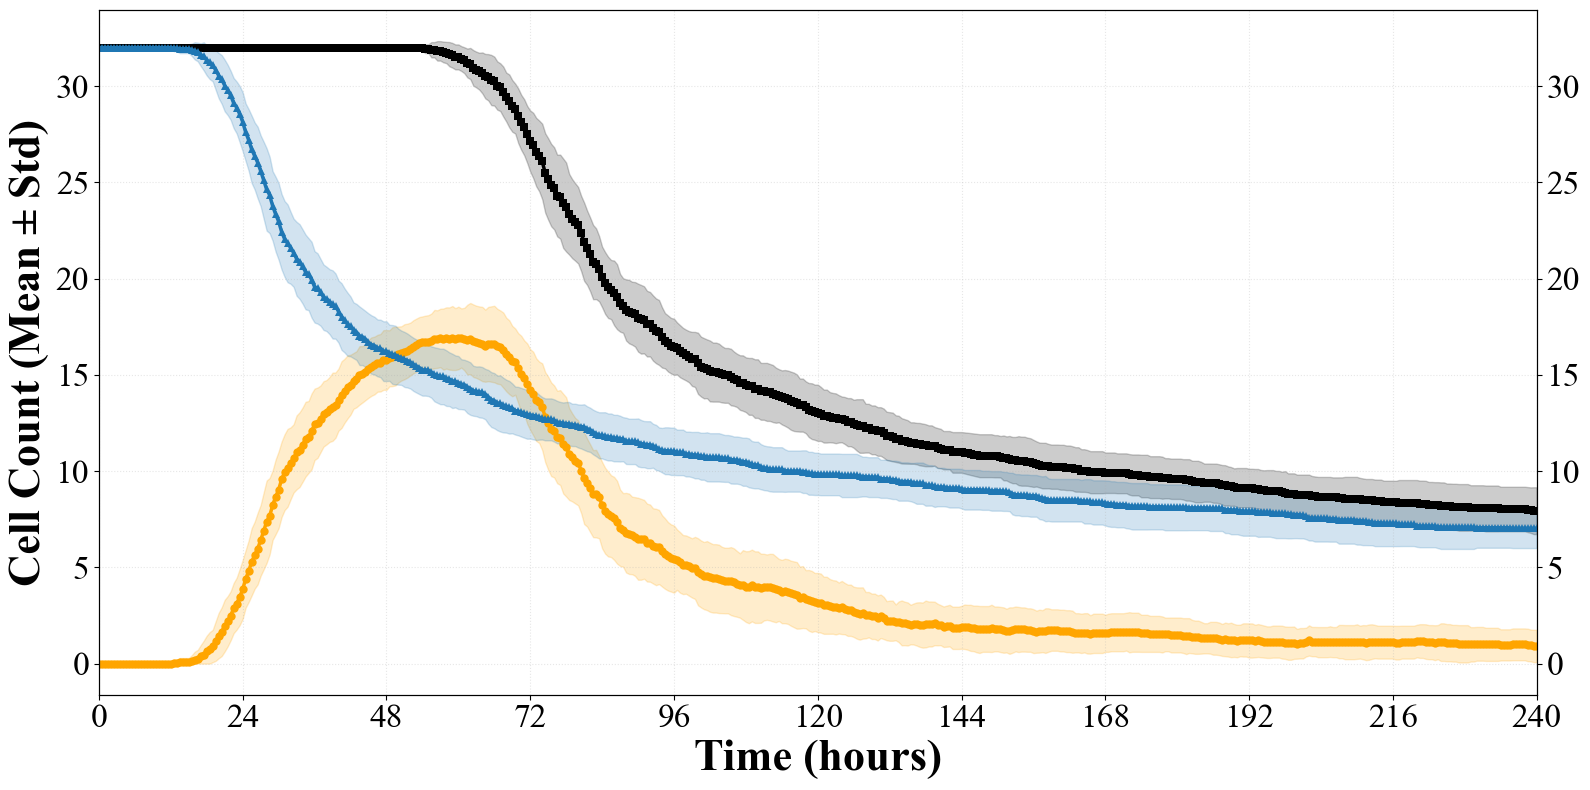

Saved combined evolution plot: sphere_combined_evolution_PTN0.4_ESC50.0_A0.03_B0.2_initial_ref.png

Summary Statistics:
  Nurse cells - Initial: 0.0 ± 0.0, Final: 0.9 ± 0.8
  Germ cells - Initial: 32.0 ± 0.0, Final: 7.9 ± 1.2
  Volume ratio - Initial: 1.000 ± 0.000, Final: 3.370 ± 1.378

✓ Combined evolution plot complete!


In [66]:
# Create combined evolution plot

# Ensure the required data is available even after a kernel restart or partial rerun.
if 'df_filtered' not in locals() or df_filtered.empty:
    print('df_filtered is missing or empty; rebuilding from trajectory files...')
    df = load_all_trajectories()
    if df.empty:
        print('ERROR: No trajectory data could be loaded from TRAJ_DIR.')
    else:
        df_filtered = filter_time_points(df, time_step=2.0)
        print(f'df_filtered rebuilt with {len(df_filtered)} rows and {len(df_filtered["Time"].unique())} time points.')

if 'multi_run_params' not in locals() or getattr(multi_run_params, 'empty', True):
    if 'df_filtered' in locals() and not df_filtered.empty:
        print('multi_run_params is missing or empty; recomputing from df_filtered...')
        multi_run_params = find_parameter_sets_with_multiple_runs(df_filtered, min_runs=2)

if 'data' not in locals() or getattr(data, 'empty', True):
    print('combined summary data is missing or empty; loading from combined_data_file...')
    data = pd.read_csv(combined_data_file, sep=r'\s+', engine='python')
    print(f'Loaded combined summary data with shape {data.shape}.')

# Check if we have all the required data
if ('df_filtered' in locals() and not df_filtered.empty and
    'multi_run_params' in locals() and not multi_run_params.empty and
    'data' in locals() and not data.empty):
    # Use the first parameter set
    param_row = multi_run_params.iloc[0]
    ptn, esc, a, b = param_row['PTN'], param_row['ESC'], param_row['A'], param_row['B']
    
    print(f"=== Creating Combined Evolution Plot ===")
    print(f"Parameter set: PTN={ptn}, ESC={esc}, A={a}, B={b}")
    print(f"df_filtered rows: {len(df_filtered)}")
    print(f"multi_run_params rows: {len(multi_run_params)}")
    print(f"combined data rows: {len(data)}")
    print(f"Plot will be saved to: {OUT_DIR}\n")
    
    # Create the combined plot
    nurse_stats, germ_stats, volume_stats = plot_combined_evolution(
        df_filtered, data, ptn, esc, a, b, reference_type="initial"
    )
    
    print("\n" + "="*70)
    print("✓ Combined evolution plot complete!")
else:
    print("ERROR: Missing required data after attempted reload.")
    print(f"df_filtered present: {'df_filtered' in locals()} | empty: {getattr(df_filtered, 'empty', True)}")
    print(f"multi_run_params present: {'multi_run_params' in locals()} | empty: {getattr(multi_run_params, 'empty', True)}")
    print(f"data present: {'data' in locals()} | empty: {getattr(data, 'empty', True)}")
    print("Please ensure you have:")
    print("  1. Loaded trajectory data (df_filtered)")
    print("  2. Found multi-run parameters (multi_run_params)")
    print("  3. Loaded nurse/germ cell count data (data)")
    print("\nRun the setup cells above again if needed.")

In [71]:
def plot_volume_evolution(df_trajectory: pd.DataFrame, 
                         ptn: float, esc: float, a: float, b: float, 
                         reference_type: str = "initial"):
    """
    Plot the evolution of nurse cell volume vs non-nurse germ cell volume over time.
    
    Parameters:
    -----------
    df_trajectory : DataFrame
        The trajectory data with cell features (must include 'Radius', 'GERM', 'NurseActivation')
    ptn, esc, a, b : float
        Parameter values for filtering
    reference_type : str
        "initial" - volume relative to initial volume
        "nucleus" - volume relative to nucleus volume (GERM_CELL_RADIUS)
        "absolute" - absolute volume in cubic units
    """
    
    param_subset = df_trajectory[
        (df_trajectory['PTN'] == ptn) & 
        (df_trajectory['ESC'] == esc) & 
        (df_trajectory['A'] == a) & 
        (df_trajectory['B'] == b)
    ]
    
    if param_subset.empty:
        print(f"⚠ No trajectory data found for parameters PTN={ptn}, ESC={esc}, A={a}, B={b}")
        return None
    
    germ_subset = param_subset[param_subset['Feature'] == 'GERM']
    if not germ_subset.empty:
        germ_cells = set(germ_subset[germ_subset['Value'] == 1]['CellID'].unique())
        print(f"Total germ cells: {len(germ_cells)}")
    else:
        print(f"⚠ No GERM feature found in data")
        return None
    
    radius_data = param_subset[
        (param_subset['Feature'] == 'Radius') & 
        (param_subset['CellID'].isin(germ_cells))
    ].copy()
    
    if radius_data.empty:
        print(f"⚠ No Radius data found for germ cells")
        return None
    
    # Convert radius to volume: V = (4/3) * π * r³
    radius_data['Volume'] = (4/3) * np.pi * (radius_data['Value'] ** 3)
    
    print(f"Radius data points: {len(radius_data)}")
    
    nurse_activation = param_subset[
        (param_subset['Feature'] == 'NurseActivation') & 
        (param_subset['CellID'].isin(germ_cells))
    ]
    
    if nurse_activation.empty:
        print(f"⚠ No NurseActivation data found")
        return None
    
    nurse_cells_by_time = nurse_activation[nurse_activation['Value'] == 10].groupby(['Time', 'Run'])['CellID'].apply(set).reset_index()
    nurse_cells_by_time.rename(columns={'CellID': 'NurseCells'}, inplace=True)
    
    print(f"Time points with nurse cell data: {len(nurse_cells_by_time)}")
    
    if reference_type == "nucleus":
        reference_volume = (4/3) * np.pi * (GERM_CELL_RADIUS ** 3)
        radius_data['VolumeMetric'] = radius_data['Volume'] / reference_volume
        ylabel = 'Volume / Nucleus Volume'
    elif reference_type == "initial":
        # Calculate initial volume for each cell in each run
        initial_volumes = radius_data.groupby(['CellID', 'Run'])['Volume'].first().reset_index()
        initial_volumes.rename(columns={'Volume': 'InitialVolume'}, inplace=True)
        radius_data = radius_data.merge(initial_volumes, on=['CellID', 'Run'])
        radius_data['VolumeMetric'] = radius_data['Volume'] / radius_data['InitialVolume']
        ylabel = 'Volume Ratio (Current / Initial)'
    else:  # "absolute"
        radius_data['VolumeMetric'] = radius_data['Volume']
        ylabel = 'Volume (μm³)'
    
    # Merge nurse cell information
    radius_data = radius_data.merge(nurse_cells_by_time, on=['Time', 'Run'], how='left')
    
    # Determine if each cell is a nurse at each time point
    def is_nurse(row):
        if pd.isna(row['NurseCells']) or not isinstance(row['NurseCells'], set):
            return False
        return row['CellID'] in row['NurseCells']
    
    radius_data['IsNurse'] = radius_data.apply(is_nurse, axis=1)
    
    # Separate data
    nurse_volumes = radius_data[radius_data['IsNurse'] == True]
    non_nurse_volumes = radius_data[radius_data['IsNurse'] == False]
    
    print(f"Nurse volume data points: {len(nurse_volumes)}")
    print(f"Non-nurse volume data points: {len(non_nurse_volumes)}")
    
    # Aggregate across all cells and runs for each time point
    nurse_stats = nurse_volumes.groupby('Time')['VolumeMetric'].agg(['mean', 'std', 'min', 'max', 'count']).reset_index()
    nurse_stats.columns = ['Time', 'Mean', 'Std', 'Min', 'Max', 'Count']
    
    non_nurse_stats = non_nurse_volumes.groupby('Time')['VolumeMetric'].agg(['mean', 'std', 'min', 'max', 'count']).reset_index()
    non_nurse_stats.columns = ['Time', 'Mean', 'Std', 'Min', 'Max', 'Count']
    
    fig, ax = plt.subplots(figsize=(16, 8))
    
    # Colorblind-friendly palette
    color_nurse = '#E69F00'  # Orange - safe for all colorblind types
    color_non_nurse = '#0173B2'  # Blue - safe for all colorblind types
    color_threshold_line = '#9467BD'  # Purple - neutral and visible to all
    
    # ==================== Plot Individual Run Variations ====================
    # Get unique runs
    runs = radius_data['Run'].unique()
    
    # Plot extreme value envelopes (min-max range) - lightest shade
    if not nurse_volumes.empty and not nurse_stats.empty:
        ax.fill_between(nurse_stats['Time'], 
                       nurse_stats['Min'], 
                       nurse_stats['Max'],
                       color=color_nurse, alpha=0.2, zorder=0, 
                       label='Nurse Cells (Min-Max Range)')
    
    if not non_nurse_volumes.empty and not non_nurse_stats.empty:
        ax.fill_between(non_nurse_stats['Time'], 
                       non_nurse_stats['Min'], 
                       non_nurse_stats['Max'],
                       color=color_non_nurse, alpha=0.2, zorder=0,
                       label='Non-Nurse Cells (Min-Max Range)')
    
    # Plot nurse cell mean
    if not nurse_stats.empty:
        ax.fill_between(nurse_stats['Time'], 
                       nurse_stats['Mean'] - nurse_stats['Std'], 
                       nurse_stats['Mean'] + nurse_stats['Std'],
                       color=color_nurse, alpha=0.4, zorder=2)
        ax.plot(nurse_stats['Time'], nurse_stats['Mean'], 
               color=color_nurse, marker='o', markersize=6, linewidth=2.5,
               label='Nurse Cells (Mean ± Std)', markeredgewidth=0, zorder=3)
    
    # Plot non-nurse cell mean
    if not non_nurse_stats.empty:
        ax.fill_between(non_nurse_stats['Time'], 
                       non_nurse_stats['Mean'] - non_nurse_stats['Std'], 
                       non_nurse_stats['Mean'] + non_nurse_stats['Std'],
                       color=color_non_nurse, alpha=0.4, zorder=2)
        ax.plot(non_nurse_stats['Time'], non_nurse_stats['Mean'], 
               color=color_non_nurse, marker='s', markersize=6, linewidth=2.5,
               label='Non-Nurse Germ Cells / Pro-Oocytes (Mean ± Std)', markeredgewidth=0, zorder=3)
    
    ax.set_xlabel('Time (hours)', fontsize=32, fontweight='bold', fontfamily='Times New Roman')
    ax.set_ylabel(ylabel, fontsize=32, fontweight='bold', fontfamily='Times New Roman')
    ax.tick_params(axis='both', labelsize=24)
    ax.grid(True, alpha=0.3, linestyle=':', linewidth=0.8)
    
    # Set Times New Roman for tick labels (the numbers on axes)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontfamily('Times New Roman')
    
    # Limit x-axis
    ax.set_xlim(left=0, right=max(nurse_stats['Time'].max() if not nurse_stats.empty else 0,
                                   non_nurse_stats['Time'].max() if not non_nurse_stats.empty else 0))
    ax.set_xticks(np.arange(0, 241, 24))
    

    plt.tight_layout()
    
    # Save plot
    filename = f"{target_shape}_volume_evolution_PTN{ptn}_ESC{esc}_A{a}_B{b}_{reference_type}_ref.png"
    plt.savefig(OUT_DIR / filename, dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f" Saved volume evolution plot: {filename}")
    
    
    
    return nurse_stats, non_nurse_stats

In [68]:
def plot_relative_volume_per_cell(
    df_trajectory: pd.DataFrame,
    ptn: float,
    esc: float,
    a: float,
    b: float,
    cell_ids=None,
    out_dir=None,
    show=False,
    dpi=300,
):
    """Plot current volume / initial volume separately for each germ cell."""
    param_subset = df_trajectory[
        (df_trajectory["PTN"] == ptn)
        & (df_trajectory["ESC"] == esc)
        & (df_trajectory["A"] == a)
        & (df_trajectory["B"] == b)
    ].copy()

    germ = param_subset[
        (param_subset["Feature"] == "GERM") & (param_subset["Value"] == 1)
    ]
    germ_cells = sorted(germ["CellID"].unique())
    if cell_ids is not None:
        germ_cells = [cell_id for cell_id in germ_cells if cell_id in cell_ids]

    radius = param_subset[
        (param_subset["Feature"] == "Radius")
        & (param_subset["CellID"].isin(germ_cells))
    ].copy()
    if radius.empty:
        print("No germ-cell radius data found for this parameter set.")
        return {}

    radius["Volume"] = (4 / 3) * np.pi * radius["Value"] ** 3
    initial = radius.groupby(["CellID", "Run"])["Volume"].first().rename("InitialVolume")
    radius = radius.join(initial, on=["CellID", "Run"])
    radius["RelativeVolume"] = radius["Volume"] / radius["InitialVolume"]

    stats = (
        radius.groupby(["CellID", "Time"])["RelativeVolume"]
        .agg(Mean="mean", Std="std", Min="min", Max="max", Count="count")
        .reset_index()
    )

    if out_dir is not None:
        out_dir = Path(out_dir)
        out_dir.mkdir(parents=True, exist_ok=True)

    outputs = {}
    for cell_id, cell_stats in stats.groupby("CellID"):
        fig, ax = plt.subplots(figsize=(16, 8))
        time = cell_stats["Time"].to_numpy()
        mean = cell_stats["Mean"].to_numpy()
        std = cell_stats["Std"].fillna(0).to_numpy()

        ax.fill_between(time, cell_stats["Min"], cell_stats["Max"],
                        color="steelblue", alpha=0.12,
                        label="minimum-maximum range")
        ax.fill_between(time, np.maximum(mean - std, 0), mean + std,
                        color="steelblue", alpha=0.25,
                        label="mean +/- standard deviation")
        ax.plot(time, mean, color="steelblue", marker='s', markersize=6, linewidth=2.5,
                label="mean relative volume", markeredgewidth=0, zorder=3)
        ax.axhline(1.0, color="orange", linestyle="--", linewidth=1.5,
                   label="initial volume")
        # ax.set_title(f"Cell {int(cell_id)}: relative-volume evolution", fontsize=15)
        ax.set_xlabel('Time (hours)', fontsize=32, fontweight='bold', fontfamily='Times New Roman')
        ax.set_ylabel("Volume Ratio (Current / Initial)", fontsize=32, fontweight='bold', fontfamily='Times New Roman')
        ax.tick_params(axis='both', labelsize=28)
        ax.grid(True, alpha=0.3, linestyle=':', linewidth=0.8)
        
        # Set Times New Roman for tick labels (the numbers on axes)
        for label in ax.get_xticklabels() + ax.get_yticklabels():
            label.set_fontfamily('Times New Roman')
        
        # Limit x-axis
        ax.set_xlim(left=0, right=max(stats['Time'].max() if not stats.empty else 0,
                                    stats['Time'].max() if not stats.empty else 0))
        ax.set_xticks(np.arange(0, 241, 24))


        fig.tight_layout()
        if out_dir is not None:
            filename = out_dir / f"{target_shape}_cell_{int(cell_id)}_relative_volume.png"
            fig.savefig(filename, dpi=dpi, bbox_inches="tight")
            outputs[int(cell_id)] = filename
        if show:
            plt.show()
        plt.close(fig)

    return outputs


Total germ cells: 32
Radius data points: 76062
Time points with nurse cell data: 3431
Nurse volume data points: 20984
Non-nurse volume data points: 55078


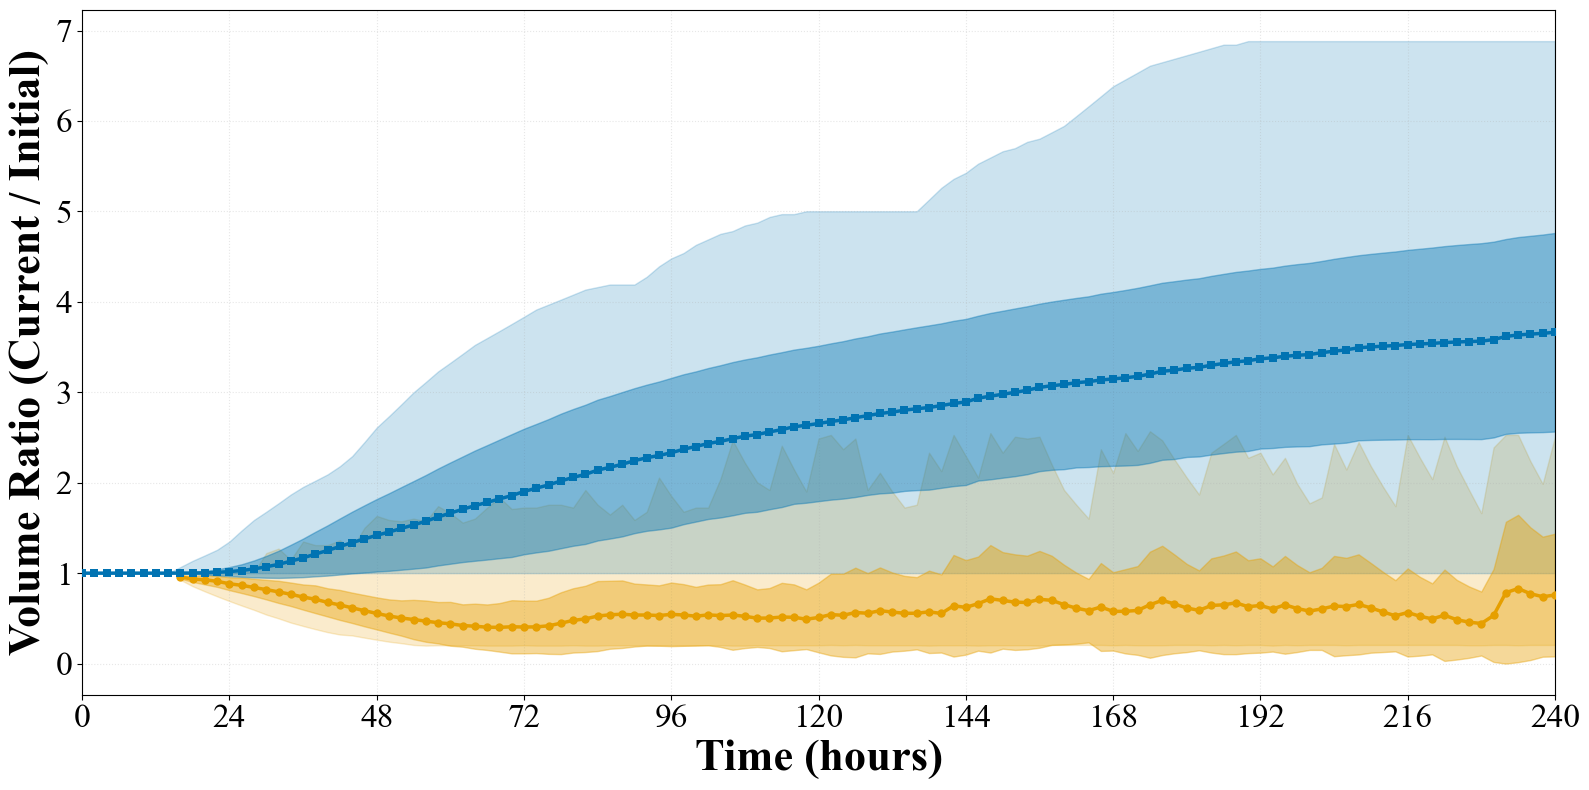

 Saved volume evolution plot: sphere_volume_evolution_PTN0.4_ESC50.0_A0.03_B0.2_initial_ref.png


In [72]:
# Create volume evolution plot

# Check if we have the required data
if 'df_filtered' in locals() and not df_filtered.empty and 'multi_run_params' in locals():
    # Use the first parameter set
    param_row = multi_run_params.iloc[0]
    ptn, esc, a, b = param_row['PTN'], param_row['ESC'], param_row['A'], param_row['B']
    
    # Create the volume plot with initial reference
    nurse_vol_stats, non_nurse_vol_stats = plot_volume_evolution(
        df_filtered, ptn, esc, a, b, reference_type="initial"
    )
    
    
else:
    print("Required data not available. Please run the data loading cells first.")

In [70]:
# Create one relative-volume plot per germ cell

if "df_filtered" in locals() and not df_filtered.empty and "multi_run_params" in locals():
    param_row = multi_run_params.iloc[0]
    cell_volume_plots = plot_relative_volume_per_cell(
        df_filtered,
        param_row["PTN"],
        param_row["ESC"],
        param_row["A"],
        param_row["B"],
        cell_ids=list(range(129, 161)),
        out_dir=OUT_DIR,
        show=False,
    )
    print(f"Saved {len(cell_volume_plots)} per-cell relative-volume plots.")
else:
    print("Run the trajectory-loading and parameter-selection cells first.")


Saved 32 per-cell relative-volume plots.
